<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/lesson2/Lesson2_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 2 — Dot Products, Neural Similarity, Weighted Inputs, and Projection

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 1 — Linear Algebra I\
**Lesson:** Lesson 2\
**Notebook type:** Teaching notebook

> *"One operation, the dot product, tells us whether two neural activity patterns point the same way, how strongly a neuron responds to its inputs, and how much of a signal lies along a direction we care about."*

---

### From one vector to two

Lesson 1 treated each population state or feature list as a single vector, and measured it on its own: its length, its direction, its distance from another vector.

Lesson 2 asks about the **relationship between two vectors**. Do two population responses have the same *pattern*? How much input does a neuron receive from a set of presynaptic cells? How much of a response lies along a direction we care about? All three questions are answered by the same operation: the **dot product**.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lesson 1.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As in Lesson 1, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. A few of them are animated: press **Play**, or drag the slider.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

# Colab picks its own renderer. Elsewhere (Jupyter, VS Code), load plotly.js with each figure,
# as Colab does, so every saved figure displays on its own.
if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'

# Background gridlines off in the template used throughout.
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_MARKERS = ['circle', 'square', 'triangle-up', 'diamond', 'triangle-down', 'cross']

PLOTLY_CONFIG = {
    'displaylogo': False,
    'responsive': True,
    'scrollZoom': True,
    'toImageButtonOptions': {
        'format': 'png',
        'scale': 2,
    },
}

def padded_limits(values, fraction=0.08, minimum_padding=1.0):
    # Return stable axis limits with a small padding around the data.
    values = np.asarray(values, dtype=float)
    lo = float(np.nanmin(values))
    hi = float(np.nanmax(values))
    span = hi - lo
    pad = minimum_padding if span == 0 else fraction * span
    return lo - pad, hi + pad

def play_pause_and_slider(labels, prefix):
    # Play/Pause buttons and a frame slider, as used in the Lesson 1 animations.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': 60, 'redraw': False}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[
            dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': False}, 'transition': {'duration': 0}}])
            for k, lab in enumerate(labels)
        ],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: are two brain states alike?**

Three neurons are recorded under three conditions (firing rates in spikes/s):

$$\mathbf{r}_A = (10,\ 30,\ 20), \qquad \mathbf{r}_{A,\text{strong}} = (20,\ 60,\ 40), \qquad \mathbf{r}_B = (30,\ 10,\ 20)$$

$\mathbf{r}_{A,\text{strong}}$ is the *same pattern* as $\mathbf{r}_A$, just twice as strong (for example, the same stimulus at higher contrast). $\mathbf{r}_B$ is a *different pattern*: N1 and N2 have swapped roles.

**Predict first:** using the Euclidean distance from Lesson 1, which state is closer to $\mathbf{r}_A$?

In [3]:
r_A        = np.array([10.0, 30.0, 20.0])   # spikes/s, (N1, N2, N3)
r_A_strong = np.array([20.0, 60.0, 40.0])   # same pattern, twice the strength
r_B        = np.array([30.0, 10.0, 20.0])   # different pattern

print(f"Distance from r_A to r_A_strong: {np.linalg.norm(r_A - r_A_strong):.1f} spikes/s")
print(f"Distance from r_A to r_B       : {np.linalg.norm(r_A - r_B):.1f} spikes/s")

Distance from r_A to r_A_strong: 37.4 spikes/s
Distance from r_A to r_B       : 28.3 spikes/s


Distance says $\mathbf{r}_B$ is closer, even though $\mathbf{r}_{A,\text{strong}}$ has exactly the same pattern as $\mathbf{r}_A$. Distance mixes together two things: **how strongly** the population fired and **which pattern** it fired in. By the end of this lesson we will have a measure that separates them.

The same operation appears in machine learning. A linear model scores one house (the Lesson 1 example) with a **weighted sum** of its features plus an offset:

In [4]:
x_house = np.array([1416.0, 3.0, 40.0])   # size (sq ft), bedrooms, age (years)
w_house = np.array([0.12, 8.0, -0.9])     # £1000s per sq ft, per bedroom, per year (made-up values)
b_house = 50.0                            # £1000s, baseline price

price = w_house @ x_house + b_house
print(f"Predicted price: {price:.1f} thousand pounds")

Predicted price: 207.9 thousand pounds


The `@` in that cell is a **dot product**. The weights here are invented for illustration; how to *fit* them from data is Lesson 5.

# **Part 1: The Dot Product as a Sum of Products**

A neuron receives input from $n$ presynaptic neurons. Input $i$ fires at rate $x_i$ and reaches the neuron through a connection of weight $w_i$. The **total weighted input** is

$$z = \mathbf{w} \cdot \mathbf{x} = \sum_{i=1}^{n} w_i x_i = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n$$

Multiply matching coordinates, then add. This only makes sense if:

- $\mathbf{w}$ and $\mathbf{x}$ have the **same number of coordinates**, and
- coordinate $i$ of $\mathbf{w}$ refers to the **same input** as coordinate $i$ of $\mathbf{x}$.

**Units.** If $x_i$ is in spikes/s and $w_i$ has no units, every term $w_i x_i$, and so $z$, is in spikes/s.

In [5]:
x_inputs  = np.array([20.0, 10.0, 5.0, 15.0])   # presynaptic firing rates, spikes/s, shape (4,)
w_weights = np.array([0.8, -0.5, 0.3, 0.0])      # connection weights (no units), shape (4,)

# Three ways to compute the same number
manual = w_weights[0]*x_inputs[0] + w_weights[1]*x_inputs[1] + w_weights[2]*x_inputs[2] + w_weights[3]*x_inputs[3]

loop_total = 0.0
for w_i, x_i in zip(w_weights, x_inputs):
    loop_total += w_i * x_i

numpy_dot = w_weights @ x_inputs          # same as np.dot(w_weights, x_inputs)

print(f"Written out by hand: {manual:.2f} spikes/s")
print(f"Python loop        : {loop_total:.2f} spikes/s")
print(f"NumPy (w @ x)      : {numpy_dot:.2f} spikes/s")

Written out by hand: 12.50 spikes/s
Python loop        : 12.50 spikes/s
NumPy (w @ x)      : 12.50 spikes/s


Each term $w_i x_i$ is one input's **contribution**. A negative weight turns a positive input into a negative contribution, which *lowers* the total.

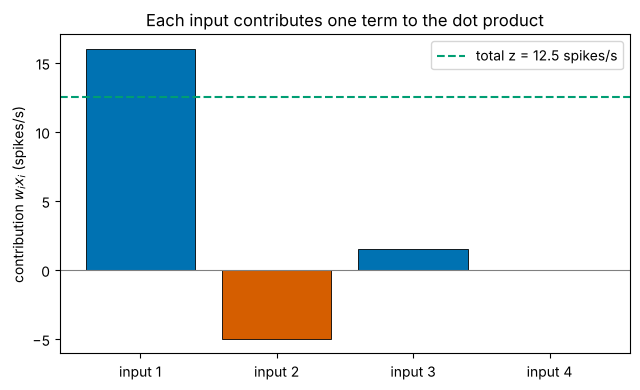

In [6]:
contributions = w_weights * x_inputs      # elementwise products, shape (4,)
labels = ['input 1', 'input 2', 'input 3', 'input 4']
bar_colours = [PALETTE[0] if c >= 0 else PALETTE[1] for c in contributions]

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(labels, contributions, color=bar_colours, edgecolor='black', linewidth=0.6)
ax.axhline(0, color='grey', lw=0.8)
ax.axhline(contributions.sum(), color=PALETTE[2], ls='--', lw=1.5, label=f'total z = {contributions.sum():.1f} spikes/s')
ax.set_ylabel(r'contribution $w_i x_i$ (spikes/s)')
ax.set_title('Each input contributes one term to the dot product')
ax.legend()
plt.tight_layout()
plt.show()

#### Interactive version

In [7]:
fig_interactive = go.Figure()
fig_interactive.add_trace(go.Bar(
    x=labels, y=contributions,
    marker_color=bar_colours, marker_line_color='black', marker_line_width=0.8,
    customdata=np.stack([w_weights, x_inputs], axis=1),
    hovertemplate=('%{x}<br>weight w_i = %{customdata[0]:.2f}<br>'
                   'input x_i = %{customdata[1]:.1f} spikes/s<br>'
                   'contribution = %{y:.2f} spikes/s<extra></extra>'),
    name='contribution',
))
fig_interactive.add_hline(y=0, line_width=1, line_color='grey')
fig_interactive.add_hline(y=contributions.sum(), line_dash='dash', line_color=PALETTE[2],
                          annotation_text=f'total z = {contributions.sum():.1f}', annotation_position='top left')
fig_interactive.update_layout(
    title='Each input contributes one term to the dot product (hover for detail)',
    yaxis_title='contribution w_i x_i (spikes/s)',
    template='plotly_white', width=680, height=440,
)
fig_interactive.show(config=PLOTLY_CONFIG)

**Order matters.** NumPy will happily compute a dot product between vectors whose coordinates refer to *different* things. It raises an error only when the lengths differ.

In [8]:
# Same numbers, but inputs 1 and 2 listed in swapped order: no error, wrong answer.
x_wrong_order = x_inputs[[1, 0, 2, 3]]
print("Correct order:", w_weights @ x_inputs, "spikes/s")
print("Wrong order  :", w_weights @ x_wrong_order, "spikes/s   <- no error raised")

# Different lengths: NumPy does raise an error.
try:
    w_weights @ np.array([20.0, 10.0, 5.0])
except ValueError as err:
    print("\nLength mismatch caught:", err)

Correct order: 12.5 spikes/s
Wrong order  : -0.5 spikes/s   <- no error raised

Length mismatch caught: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 4)


# **Part 2: Properties and the Self Dot Product**

For vectors $\mathbf{u}, \mathbf{v}, \mathbf{w}$ of the same length and a number $c$:

| Property | Statement | What it means here |
|---|---|---|
| Order does not matter | $\mathbf{u}\cdot\mathbf{v} = \mathbf{v}\cdot\mathbf{u}$ | Comparing A to B gives the same number as B to A |
| Sums split | $\mathbf{u}\cdot(\mathbf{v}+\mathbf{w}) = \mathbf{u}\cdot\mathbf{v} + \mathbf{u}\cdot\mathbf{w}$ | Two input sources add their weighted contributions |
| Scaling passes through | $\mathbf{u}\cdot(c\,\mathbf{v}) = c\,(\mathbf{u}\cdot\mathbf{v})$ | Doubling every input doubles the total input |
| Self dot product | $\mathbf{v}\cdot\mathbf{v} = \lVert\mathbf{v}\rVert^2$ | Links the dot product to the Lesson 1 norm |

The last row means $\lVert\mathbf{v}\rVert = \sqrt{\mathbf{v}\cdot\mathbf{v}}$: the norm from Lesson 1 *is* a dot product.

In [9]:
u = np.array([2.0, -1.0, 3.0])
v = np.array([0.5, 4.0, -2.0])
w = np.array([1.0, 1.0, 1.0])
c = 3.0

print("u.v == v.u            :", np.isclose(u @ v, v @ u))
print("u.(v+w) == u.v + u.w  :", np.isclose(u @ (v + w), u @ v + u @ w))
print("u.(c v) == c (u.v)    :", np.isclose(u @ (c * v), c * (u @ v)))
print(f"v.v = {v @ v:.2f}   ||v||^2 = {np.linalg.norm(v)**2:.2f}")

u.v == v.u            : True
u.(v+w) == u.v + u.w  : True
u.(c v) == c (u.v)    : True
v.v = 20.25   ||v||^2 = 20.25


# **Part 3: The Geometric View: Length and Angle**

The same number has a second formula, in terms of lengths and the angle $\theta$ between the two vectors:

$$\mathbf{u}\cdot\mathbf{v} = \lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert\cos\theta$$

Rearranging gives the angle:

$$\cos\theta = \frac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert}, \qquad \theta = \arccos\!\left(\frac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert}\right)$$

The **sign** of the dot product tells you the kind of angle:

- $\mathbf{u}\cdot\mathbf{v} > 0$: acute angle, the vectors point broadly the same way.
- $\mathbf{u}\cdot\mathbf{v} = 0$: right angle ($90^\circ$).
- $\mathbf{u}\cdot\mathbf{v} < 0$: obtuse angle, the vectors point broadly opposite ways.

Rounding can push the ratio a hair outside $[-1, 1]$ (e.g. `1.0000000002`), where `np.arccos` returns `nan`. Clipping first with `np.clip` prevents this.

In [10]:
def angle_between(a, b, eps=1e-12):
    # Angle in degrees between two nonzero vectors.
    norm_a, norm_b = np.linalg.norm(a), np.linalg.norm(b)
    if norm_a < eps or norm_b < eps:
        raise ValueError("The angle is undefined for a zero vector.")
    cos_theta = np.clip((a @ b) / (norm_a * norm_b), -1.0, 1.0)
    return np.degrees(np.arccos(cos_theta))

print(f"Angle between r_A and r_A_strong: {angle_between(r_A, r_A_strong):5.1f} degrees")
print(f"Angle between r_A and r_B       : {angle_between(r_A, r_B):5.1f} degrees")

Angle between r_A and r_A_strong:   0.0 degrees
Angle between r_A and r_B       :  44.4 degrees


The angle answers the motivation question: $\mathbf{r}_{A,\text{strong}}$ points in *exactly* the same direction as $\mathbf{r}_A$ ($0^\circ$), while $\mathbf{r}_B$ is $44^\circ$ away.

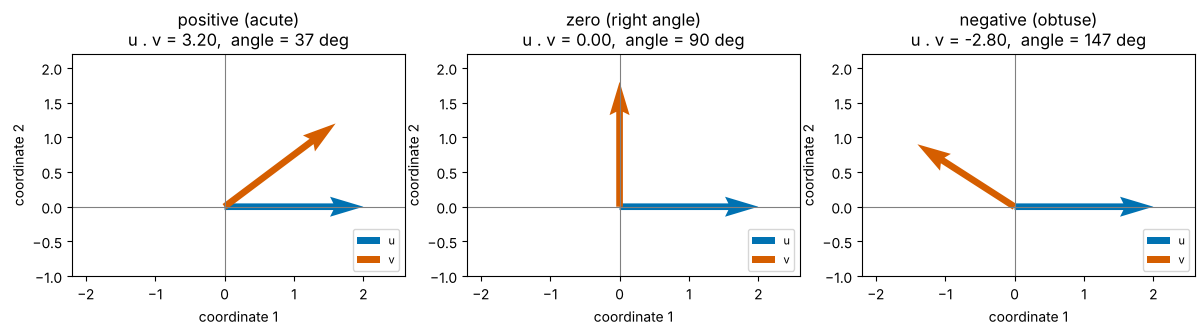

In [11]:
# Positive, zero, and negative dot products in 2D
u_fixed = np.array([2.0, 0.0])
cases = {
    'positive (acute)':   np.array([1.6, 1.2]),
    'zero (right angle)': np.array([0.0, 1.8]),
    'negative (obtuse)':  np.array([-1.4, 0.9]),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
qkw = dict(angles='xy', scale_units='xy', scale=1, width=0.02)
for ax, (label, v_case) in zip(axes, cases.items()):
    ax.quiver(0, 0, *u_fixed, color=PALETTE[0], label='u', **qkw)
    ax.quiver(0, 0, *v_case, color=PALETTE[1], label='v', **qkw)
    ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
    ax.set_xlim(-2.2, 2.6); ax.set_ylim(-1.0, 2.2)
    ax.set_aspect('equal')
    ax.set_xlabel('coordinate 1'); ax.set_ylabel('coordinate 2')
    ax.set_title(f"{label}\nu . v = {u_fixed @ v_case:.2f},  angle = {angle_between(u_fixed, v_case):.0f} deg")
    ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

#### Animation: rotate $\mathbf{v}$ and watch the dot product

$\mathbf{u}$ stays fixed while $\mathbf{v}$ turns through a full circle. The right panel traces $\mathbf{u}\cdot\mathbf{v}$ against the angle.

In [12]:
# INTERACTIVE ANIMATION -- rotating v, with the dot product traced against the angle
angles_deg = np.arange(0, 361, 5)
angles_rad = np.radians(angles_deg)
v_length = 1.8
v_rotating = v_length * np.stack([np.cos(angles_rad), np.sin(angles_rad)], axis=1)   # shape (n_angles, 2)
dot_values = v_rotating @ u_fixed                                                    # shape (n_angles,)

fig_rotation = make_subplots(rows=1, cols=2, column_widths=[0.42, 0.58],
                             subplot_titles=('u fixed, v rotating', 'u . v against the angle'))
fig_rotation.add_trace(go.Scatter(x=[0, u_fixed[0]], y=[0, u_fixed[1]], mode='lines+markers', name='u (fixed)',
                                  line=dict(color=PALETTE[0], width=5),
                                  marker=dict(size=[1, 12], symbol=['circle', 'triangle-right'], color=PALETTE[0])), row=1, col=1)
fig_rotation.add_trace(go.Scatter(x=[0, v_rotating[0, 0]], y=[0, v_rotating[0, 1]], mode='lines', name='v (rotating)',
                                  line=dict(color=PALETTE[1], width=5)), row=1, col=1)
fig_rotation.add_trace(go.Scatter(x=angles_deg, y=dot_values, mode='lines', name='u . v (full curve)',
                                  line=dict(color='lightgrey', width=2), hoverinfo='skip'), row=1, col=2)
fig_rotation.add_trace(go.Scatter(x=[angles_deg[0]], y=[dot_values[0]], mode='markers', name='current angle',
                                  marker=dict(color=PALETTE[2], size=12)), row=1, col=2)
fig_rotation.add_hline(y=0, line_width=1, line_color='grey', row=1, col=2)
for right_angle in (90, 270):
    fig_rotation.add_vline(x=right_angle, line_dash='dot', line_color=PALETTE[3], row=1, col=2)

fig_rotation.frames = [
    go.Frame(name=str(k), traces=[1, 3], data=[
        go.Scatter(x=[0, v_rotating[k, 0]], y=[0, v_rotating[k, 1]]),
        go.Scatter(x=[angles_deg[k]], y=[dot_values[k]]),
    ])
    for k in range(len(angles_deg))
]
buttons, sliders = play_pause_and_slider([f'{a} deg' for a in angles_deg], prefix='angle = ')
fig_rotation.update_xaxes(range=[-2.4, 2.4], title_text='coordinate 1', scaleanchor='y', scaleratio=1, row=1, col=1)
fig_rotation.update_yaxes(range=[-2.4, 2.4], title_text='coordinate 2', row=1, col=1)
fig_rotation.update_xaxes(range=[0, 360], title_text='angle (degrees)', row=1, col=2)
fig_rotation.update_yaxes(range=list(padded_limits(dot_values)), title_text='u . v', row=1, col=2)
fig_rotation.update_layout(title='Rotating v: the dot product follows a cosine', template='plotly_white',
                           width=980, height=520, updatemenus=buttons, sliders=sliders)
fig_rotation.show(config=PLOTLY_CONFIG)

The curve is a cosine: largest when $\mathbf{v}$ points along $\mathbf{u}$, zero at $90^\circ$ and $270^\circ$ (dotted lines), most negative when $\mathbf{v}$ points the opposite way.

# **Part 4: Orthogonality**

Two vectors are **orthogonal** when their dot product is zero: they meet at a right angle.

**Neuroscience context.** Suppose two downstream neurons read out the same three-neuron population with weights $\mathbf{w}_1 = (1, 1, 0)$ and $\mathbf{w}_2 = (1, -1, 0)$. These two weight vectors are orthogonal. A population change *along* $\mathbf{w}_1$ moves the first read-out but leaves the second exactly unchanged.

In [13]:
w_readout_1 = np.array([1.0, 1.0, 0.0])
w_readout_2 = np.array([1.0, -1.0, 0.0])
print("w_readout_1 . w_readout_2 =", w_readout_1 @ w_readout_2)

delta_r = np.array([5.0, 5.0, 0.0])   # spikes/s: N1 and N2 both increase by 5
print(f"\nChange in read-out 1: {w_readout_1 @ delta_r:+.1f} spikes/s")
print(f"Change in read-out 2: {w_readout_2 @ delta_r:+.1f} spikes/s   <- unaffected")

w_readout_1 . w_readout_2 = 0.0

Change in read-out 1: +10.0 spikes/s
Change in read-out 2: +0.0 spikes/s   <- unaffected


**Checking for zero on a computer.** Arithmetic with decimals is approximate, so two vectors that are orthogonal on paper often give a dot product like `6e-17` rather than `0.0`. Test whether the result is *close to* zero with `np.isclose`, not `== 0`.

In [14]:
def is_orthogonal(a, b, atol=1e-8):
    return np.isclose(a @ b, 0.0, atol=atol)

# A 90-degree rotation built from cos and sin
reference = np.array([1.0, 0.0])
rotated = np.array([np.cos(np.pi / 2), np.sin(np.pi / 2)])

print("Dot product   :", reference @ rotated)
print("Exactly zero? :", reference @ rotated == 0.0)
print("Orthogonal?   :", is_orthogonal(reference, rotated))

Dot product   : 6.123233995736766e-17
Exactly zero? : False
Orthogonal?   : True


Orthogonal is a statement about geometry. It is not the same as "statistically independent", which is a statement about probability (Week 5).

# **Part 5: Normalisation and Cosine Similarity**

The geometric formula $\mathbf{u}\cdot\mathbf{v} = \lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert\cos\theta$ mixes **strength** (the two lengths) with **pattern** (the angle). To compare patterns only, divide the lengths out. That gives **cosine similarity**:

$$\operatorname{cos\_sim}(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert} = \hat{\mathbf{u}}\cdot\hat{\mathbf{v}} = \cos\theta$$

The middle form is worth noticing: cosine similarity is just the dot product of the two **unit vectors** from Lesson 1. Normalise both, then take the dot product.

- It ranges from $-1$ (opposite directions) through $0$ (orthogonal) to $+1$ (same direction).
- Multiplying either vector by a positive number does not change it.
- It is undefined for the zero vector, which has no direction.

In [15]:
def normalise(v, eps=1e-12):
    # The Lesson 1 function: unit vector of v, or an error for the zero vector.
    v = np.asarray(v, dtype=float)
    norm = np.linalg.norm(v)
    if norm < eps:
        raise ValueError("The zero vector has no defined direction.")
    return v / norm

def cosine_similarity(a, b):
    return float(np.clip(normalise(a) @ normalise(b), -1.0, 1.0))

print(f"{'pair':22s}{'distance':>12s}{'cosine similarity':>20s}")
for name, other in [('r_A vs r_A_strong', r_A_strong), ('r_A vs r_B', r_B)]:
    print(f"{name:22s}{np.linalg.norm(r_A - other):12.1f}{cosine_similarity(r_A, other):20.3f}")

pair                      distance   cosine similarity
r_A vs r_A_strong             37.4               1.000
r_A vs r_B                    28.3               0.714


Cosine similarity gives the answer the motivation asked for: $\mathbf{r}_{A,\text{strong}}$ has the same pattern as $\mathbf{r}_A$ (similarity $1.0$), and $\mathbf{r}_B$ does not.

The figure below rescales one pattern and tracks three measures. Only one of them ignores the rescaling.

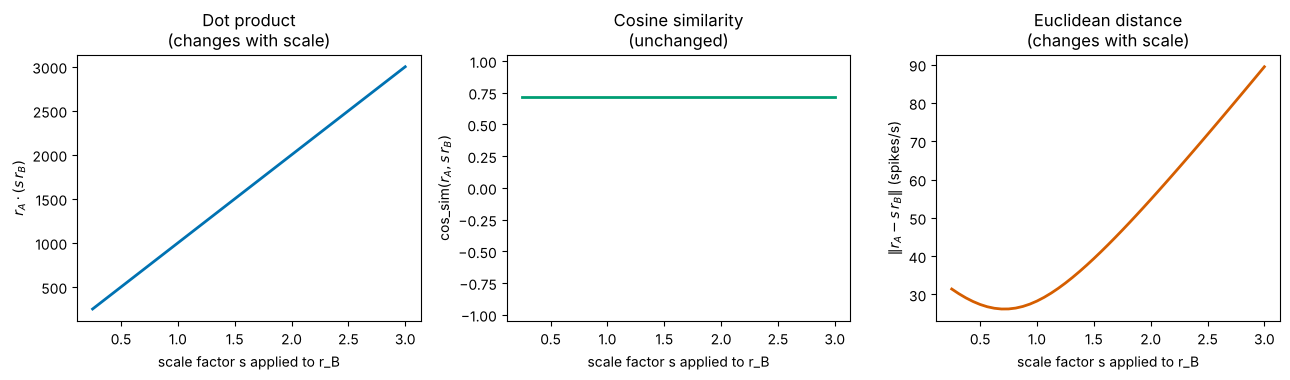

In [16]:
scale_factors = np.linspace(0.25, 3.0, 45)
dots      = np.array([r_A @ (s * r_B) for s in scale_factors])
cosines   = np.array([cosine_similarity(r_A, s * r_B) for s in scale_factors])
distances = np.array([np.linalg.norm(r_A - s * r_B) for s in scale_factors])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, values, colour, title, ylabel in [
    (axes[0], dots, PALETTE[0], 'Dot product\n(changes with scale)', r'$r_A \cdot (s\, r_B)$'),
    (axes[1], cosines, PALETTE[2], 'Cosine similarity\n(unchanged)', r'cos_sim$(r_A, s\, r_B)$'),
    (axes[2], distances, PALETTE[1], 'Euclidean distance\n(changes with scale)', r'$\|r_A - s\, r_B\|$ (spikes/s)'),
]:
    ax.plot(scale_factors, values, color=colour, lw=2)
    ax.set_xlabel('scale factor s applied to r_B')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[1].set_ylim(-1.05, 1.05)
plt.tight_layout()
plt.show()

#### Interactive version

In [17]:
fig_interactive = make_subplots(rows=1, cols=3, horizontal_spacing=0.08,
                                subplot_titles=('Dot product', 'Cosine similarity', 'Euclidean distance (spikes/s)'))
for col, values, colour, name in [(1, dots, PALETTE[0], 'dot product'),
                                  (2, cosines, PALETTE[2], 'cosine similarity'),
                                  (3, distances, PALETTE[1], 'distance')]:
    fig_interactive.add_trace(go.Scatter(x=scale_factors, y=values, mode='lines', name=name,
                                         line=dict(color=colour, width=3),
                                         hovertemplate='s = %{x:.2f}<br>' + name + ' = %{y:.3f}<extra></extra>'),
                              row=1, col=col)
    fig_interactive.update_xaxes(title_text='scale factor s', row=1, col=col)
fig_interactive.update_yaxes(range=[-1.05, 1.05], row=1, col=2)
fig_interactive.update_layout(title='Rescaling r_B: only cosine similarity stays the same',
                              template='plotly_white', width=1050, height=400, showlegend=False)
fig_interactive.show(config=PLOTLY_CONFIG)

**What cosine similarity removes:** overall response strength.\
**What it keeps:** the relative pattern across neurons.

Exactly the same trade-off as normalisation in Lesson 1, because it *is* normalisation followed by a dot product.

# **Part 6: Comparing Neural Population Patterns**

Four neurons are recorded while an animal views five stimuli. Each stimulus gives one population vector (simulated values, mean firing rate in spikes/s). Collecting all the pairwise cosine similarities into one table gives a **similarity matrix**, a standard way to summarise which stimuli the population treats alike.

In [18]:
neuron_labels = ['N1', 'N2', 'N3', 'N4']
grating_0 = np.array([40.0, 25.0, 8.0, 5.0])

stimulus_responses = {
    'Grating 0°':                grating_0,
    'Grating 0° (high contrast)': 1.8 * grating_0 + RNG.normal(0.0, 1.0, size=4),
    'Grating 45°':               np.array([22.0, 30.0, 24.0, 10.0]),
    'Grating 90°':               np.array([6.0, 9.0, 35.0, 28.0]),
    'Blank screen':              np.array([4.0, 5.0, 4.0, 5.0]),
}
stimulus_names = list(stimulus_responses.keys())
responses = np.stack(list(stimulus_responses.values()))   # shape (n_stimuli, n_neurons) = (5, 4)
print("responses shape:", responses.shape, " (n_stimuli, n_neurons), units: spikes/s\n")
for name, vec in stimulus_responses.items():
    print(f"  {name:28s}: {np.round(vec, 1)}")

responses shape: (5, 4)  (n_stimuli, n_neurons), units: spikes/s

  Grating 0°                  : [40. 25.  8.  5.]
  Grating 0° (high contrast)  : [72.3 44.  15.2  9.9]
  Grating 45°                 : [22. 30. 24. 10.]
  Grating 90°                 : [ 6.  9. 35. 28.]
  Blank screen                : [4. 5. 4. 5.]


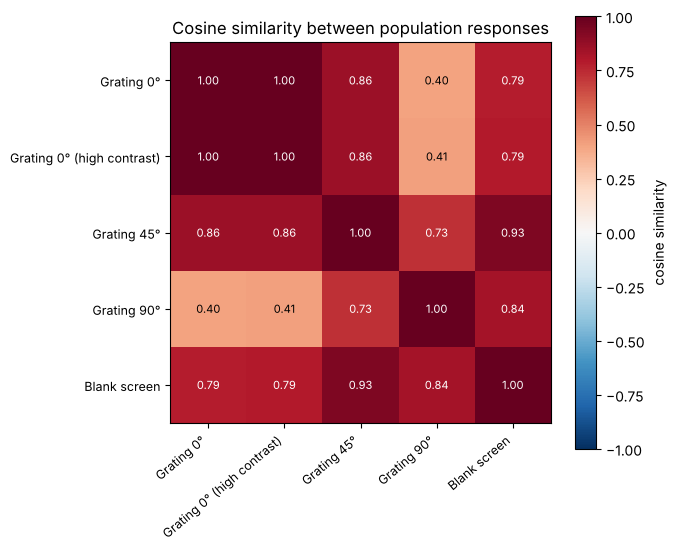

In [19]:
n_stimuli = len(stimulus_names)
similarity_matrix = np.zeros((n_stimuli, n_stimuli))
for i in range(n_stimuli):
    for j in range(n_stimuli):
        similarity_matrix[i, j] = cosine_similarity(responses[i], responses[j])

fig, ax = plt.subplots(figsize=(6.8, 5.8))
im = ax.imshow(similarity_matrix, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(n_stimuli)); ax.set_xticklabels(stimulus_names, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(n_stimuli)); ax.set_yticklabels(stimulus_names, fontsize=9)
for i in range(n_stimuli):
    for j in range(n_stimuli):
        ax.text(j, i, f'{similarity_matrix[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if similarity_matrix[i, j] > 0.6 else 'black')
ax.set_title('Cosine similarity between population responses')
fig.colorbar(im, ax=ax, label='cosine similarity')
plt.tight_layout()
plt.show()

#### Interactive version

In [20]:
fig_interactive = go.Figure(go.Heatmap(
    z=similarity_matrix, x=stimulus_names, y=stimulus_names,
    colorscale='RdBu', reversescale=True, zmin=-1, zmax=1,
    text=np.round(similarity_matrix, 2), texttemplate='%{text}',
    hovertemplate='%{y} vs %{x}<br>cosine similarity = %{z:.3f}<extra></extra>',
    colorbar=dict(title='cos_sim'),
))
fig_interactive.update_yaxes(autorange='reversed')
fig_interactive.update_layout(title='Cosine similarity between population responses',
                              template='plotly_white', width=700, height=620, xaxis=dict(tickangle=40))
fig_interactive.show(config=PLOTLY_CONFIG)

**Reading the matrix:** the two 0° gratings are almost perfectly similar (same pattern, different strength). 0° and 90° are the least similar pair, and 45° sits in between.

**But look at the blank screen.** It is a *flat* pattern with almost no structure, yet its similarity to every grating is well above zero. This happens because firing rates cannot be negative: every response vector lives in the "all-positive" corner of the space, so any two of them are already partly aligned. A shared baseline inflates cosine similarity.

One common remedy is to subtract each vector's own mean before comparing (**mean-centring**). This changes what is being compared, so it must be reported as a choice, not applied silently.

In [21]:
def mean_centre(v):
    return v - v.mean()

g0, blank = stimulus_responses['Grating 0°'], stimulus_responses['Blank screen']
print(f"Grating 0° vs Blank screen, raw          : {cosine_similarity(g0, blank):.3f}")
print(f"Grating 0° vs Blank screen, mean-centred : {cosine_similarity(mean_centre(g0), mean_centre(blank)):.3f}")

Grating 0° vs Blank screen, raw          : 0.785
Grating 0° vs Blank screen, mean-centred : -0.320


**Limitations.** High similarity between two stimuli is a fact about two measured vectors; it does not show that the brain processes them by the same mechanism. The values also depend on which neurons happened to be recorded and on preprocessing choices such as mean-centring.

# **Part 7: Projection and Projection Error**

Given a vector $\mathbf{u}$ and a direction $\mathbf{v}$, **projection** answers: *how much of $\mathbf{u}$ lies along $\mathbf{v}$?*

**Scalar projection**, a single signed number (the coordinate of $\mathbf{u}$ along $\mathbf{v}$):

$$\operatorname{comp}_{\mathbf{v}}(\mathbf{u}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\lVert\mathbf{v}\rVert} = \mathbf{u}\cdot\hat{\mathbf{v}}$$

**Vector projection**, the part of $\mathbf{u}$ that lies along $\mathbf{v}$:

$$\operatorname{proj}_{\mathbf{v}}(\mathbf{u}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\,\mathbf{v}$$

**Residual**, what is left over:

$$\mathbf{e} = \mathbf{u} - \operatorname{proj}_{\mathbf{v}}(\mathbf{u})$$

The residual is always orthogonal to $\mathbf{v}$. Its length $\lVert\mathbf{e}\rVert$ is the **projection error**: how much of $\mathbf{u}$ the direction $\mathbf{v}$ fails to capture.

If $\mathbf{v}$ is not a unit vector, forgetting to divide by $\lVert\mathbf{v}\rVert$ (or by $\mathbf{v}\cdot\mathbf{v}$) is the most common mistake.

In [22]:
def scalar_projection(u, v):
    return u @ normalise(v)

def vector_projection(u, v):
    if np.isclose(v @ v, 0.0):
        raise ValueError("Cannot project onto the zero vector.")
    return (u @ v) / (v @ v) * v

u_vec = np.array([3.0, 4.0])
v_dir = np.array([2.0, 0.5])     # not a unit vector

comp = scalar_projection(u_vec, v_dir)
proj = vector_projection(u_vec, v_dir)
residual = u_vec - proj
projection_error = np.linalg.norm(residual)

print(f"Scalar projection comp_v(u): {comp:.3f}")
print(f"Vector projection proj_v(u): {np.round(proj, 3)}")
print(f"Residual e                 : {np.round(residual, 3)}")
print(f"Projection error ||e||     : {projection_error:.3f}")
print(f"\nCheck: e . v = {residual @ v_dir:.1e}  (orthogonal)")
print(f"Check: proj + e == u ? {np.allclose(proj + residual, u_vec)}")

Scalar projection comp_v(u): 3.881
Vector projection proj_v(u): [3.765 0.941]
Residual e                 : [-0.765  3.059]
Projection error ||e||     : 3.153

Check: e . v = 0.0e+00  (orthogonal)
Check: proj + e == u ? True


**Projection error is the shortest distance to the line.** Every point on the line through $\mathbf{v}$ can be written $t\,\mathbf{v}$ for some number $t$. The right-hand panel below measures the distance from $\mathbf{u}$ to every such point. The smallest distance is reached exactly at the projection, and equals the projection error.

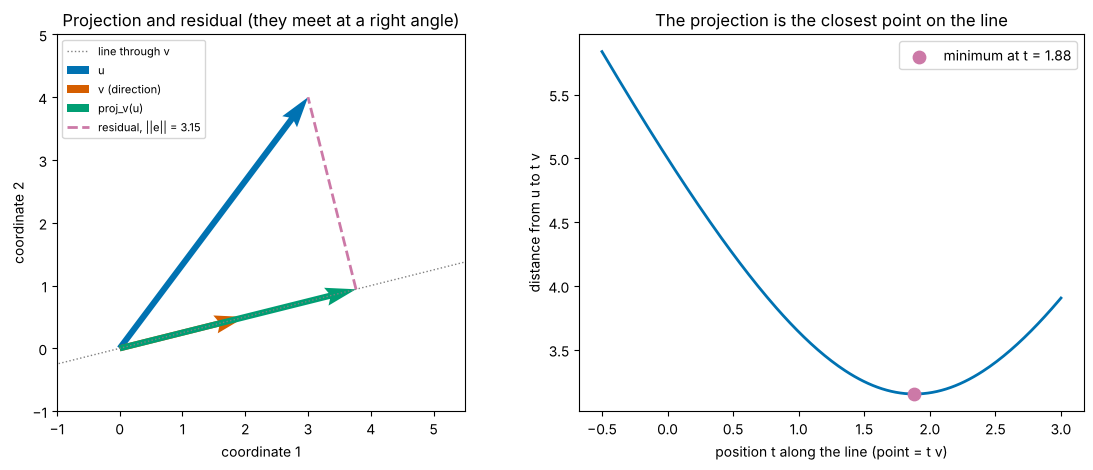

In [23]:
t_values = np.linspace(-0.5, 3.0, 201)
points_on_line = t_values[:, None] * v_dir                 # shape (201, 2)
dist_to_line = np.linalg.norm(u_vec - points_on_line, axis=1)
t_best = (u_vec @ v_dir) / (v_dir @ v_dir)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

ax = axes[0]
qkw = dict(angles='xy', scale_units='xy', scale=1, width=0.015)
line_ends = np.array([-0.6, 2.8])[:, None] * v_dir
ax.plot(line_ends[:, 0], line_ends[:, 1], ':', color='grey', lw=1, label='line through v')
ax.quiver(0, 0, *u_vec, color=PALETTE[0], label='u', **qkw)
ax.quiver(0, 0, *v_dir, color=PALETTE[1], label='v (direction)', **qkw)
ax.quiver(0, 0, *proj, color=PALETTE[2], label='proj_v(u)', **qkw)
ax.plot([proj[0], u_vec[0]], [proj[1], u_vec[1]], '--', color=PALETTE[3], lw=2, label=f'residual, ||e|| = {projection_error:.2f}')
ax.set_xlim(-1, 5.5); ax.set_ylim(-1, 5)
ax.set_aspect('equal')
ax.set_xlabel('coordinate 1'); ax.set_ylabel('coordinate 2')
ax.set_title('Projection and residual (they meet at a right angle)')
ax.legend(fontsize=8, loc='upper left')

ax = axes[1]
ax.plot(t_values, dist_to_line, color=PALETTE[0], lw=2)
ax.scatter([t_best], [projection_error], color=PALETTE[3], s=80, zorder=3, label=f'minimum at t = {t_best:.2f}')
ax.set_xlabel('position t along the line (point = t v)')
ax.set_ylabel('distance from u to t v')
ax.set_title('The projection is the closest point on the line')
ax.legend()
plt.tight_layout()
plt.show()

#### Animation: rotate the direction

$\mathbf{u}$ stays fixed while the direction turns through $180^\circ$. Watch the projection grow and shrink, and the residual (dashed) stay at a right angle to the line. The right panel tracks the projection error.

In [24]:
# INTERACTIVE ANIMATION -- rotating projection direction
direction_deg = np.arange(0, 181, 4)
directions = np.stack([np.cos(np.radians(direction_deg)), np.sin(np.radians(direction_deg))], axis=1)   # unit vectors, shape (n, 2)
projections = np.array([vector_projection(u_vec, d) for d in directions])
errors = np.linalg.norm(u_vec - projections, axis=1)
reach = 6.0

fig_proj = make_subplots(rows=1, cols=2, column_widths=[0.5, 0.5],
                         subplot_titles=('Projection onto a rotating direction', 'Projection error against direction'))
fig_proj.add_trace(go.Scatter(x=[0, u_vec[0]], y=[0, u_vec[1]], mode='lines+markers', name='u (fixed)',
                              line=dict(color=PALETTE[0], width=5),
                              marker=dict(size=[1, 12], symbol=['circle', 'triangle-up'], color=PALETTE[0])), row=1, col=1)
fig_proj.add_trace(go.Scatter(x=[-reach * directions[0, 0], reach * directions[0, 0]],
                              y=[-reach * directions[0, 1], reach * directions[0, 1]],
                              mode='lines', name='direction line', line=dict(color='grey', width=1, dash='dot')), row=1, col=1)
fig_proj.add_trace(go.Scatter(x=[0, projections[0, 0]], y=[0, projections[0, 1]], mode='lines', name='proj_v(u)',
                              line=dict(color=PALETTE[2], width=5)), row=1, col=1)
fig_proj.add_trace(go.Scatter(x=[projections[0, 0], u_vec[0]], y=[projections[0, 1], u_vec[1]], mode='lines', name='residual',
                              line=dict(color=PALETTE[3], width=3, dash='dash')), row=1, col=1)
fig_proj.add_trace(go.Scatter(x=direction_deg, y=errors, mode='lines', name='projection error (full curve)',
                              line=dict(color='lightgrey', width=2), hoverinfo='skip'), row=1, col=2)
fig_proj.add_trace(go.Scatter(x=[direction_deg[0]], y=[errors[0]], mode='markers', name='current direction',
                              marker=dict(color=PALETTE[3], size=12)), row=1, col=2)

fig_proj.frames = [
    go.Frame(name=str(k), traces=[1, 2, 3, 5], data=[
        go.Scatter(x=[-reach * directions[k, 0], reach * directions[k, 0]], y=[-reach * directions[k, 1], reach * directions[k, 1]]),
        go.Scatter(x=[0, projections[k, 0]], y=[0, projections[k, 1]]),
        go.Scatter(x=[projections[k, 0], u_vec[0]], y=[projections[k, 1], u_vec[1]]),
        go.Scatter(x=[direction_deg[k]], y=[errors[k]]),
    ])
    for k in range(len(direction_deg))
]
buttons, sliders = play_pause_and_slider([f'{a} deg' for a in direction_deg], prefix='direction = ')
fig_proj.update_xaxes(range=[-5.5, 5.5], title_text='coordinate 1', scaleanchor='y', scaleratio=1, row=1, col=1)
fig_proj.update_yaxes(range=[-5.5, 5.5], title_text='coordinate 2', row=1, col=1)
fig_proj.update_xaxes(range=[0, 180], title_text='direction angle (degrees)', row=1, col=2)
fig_proj.update_yaxes(range=[0, 5.5], title_text='projection error ||e||', row=1, col=2)
fig_proj.update_layout(title='Projection onto a rotating direction', template='plotly_white',
                       width=1000, height=540, updatemenus=buttons, sliders=sliders)
fig_proj.show(config=PLOTLY_CONFIG)

The projection error is zero when the direction lines up with $\mathbf{u}$ (about $53^\circ$), and equals $\lVert\mathbf{u}\rVert = 5$ when the direction is orthogonal to $\mathbf{u}$, because then nothing of $\mathbf{u}$ lies along it.

# **Part 8: Projecting Neural Activity onto a Task Axis**

A common analysis in systems neuroscience: record a population on many trials of two conditions, define a **task axis** that separates them, and project every trial onto it. Each trial then becomes a single number: its position along the axis.

Here two neurons are recorded on 40 trials of Stimulus A and 40 trials of Stimulus B (simulated). The task axis is the unit vector pointing from the mean B response to the mean A response:

$$\hat{\mathbf{a}} = \frac{\bar{\mathbf{r}}_A - \bar{\mathbf{r}}_B}{\lVert\bar{\mathbf{r}}_A - \bar{\mathbf{r}}_B\rVert}$$

In [25]:
n_trials = 40
mean_A = np.array([30.0, 18.0])   # spikes/s, (N1, N2)
mean_B = np.array([18.0, 28.0])
noise_sd = 4.5                     # spikes/s, trial-to-trial variability

trials_A = mean_A + RNG.normal(0.0, noise_sd, size=(n_trials, 2))   # shape (n_trials, n_neurons) = (40, 2)
trials_B = mean_B + RNG.normal(0.0, noise_sd, size=(n_trials, 2))
print("trials_A shape:", trials_A.shape, " (n_trials, n_neurons), units: spikes/s")

task_axis = normalise(trials_A.mean(axis=0) - trials_B.mean(axis=0))
print("Task axis (unit vector):", np.round(task_axis, 3))

# One dot product per trial: (40, 2) @ (2,) -> (40,)
coords_A = trials_A @ task_axis
coords_B = trials_B @ task_axis
print("coords_A shape:", coords_A.shape, " (one coordinate per trial, in spikes/s along the axis)")

trials_A shape: (40, 2)  (n_trials, n_neurons), units: spikes/s
Task axis (unit vector): [ 0.804 -0.594]
coords_A shape: (40,)  (one coordinate per trial, in spikes/s along the axis)


`trials_A @ task_axis` computes 40 dot products at once, one per row. This "many dot products in one line" pattern is exactly what a matrix–vector product is, the topic of Lessons 3 and 4.

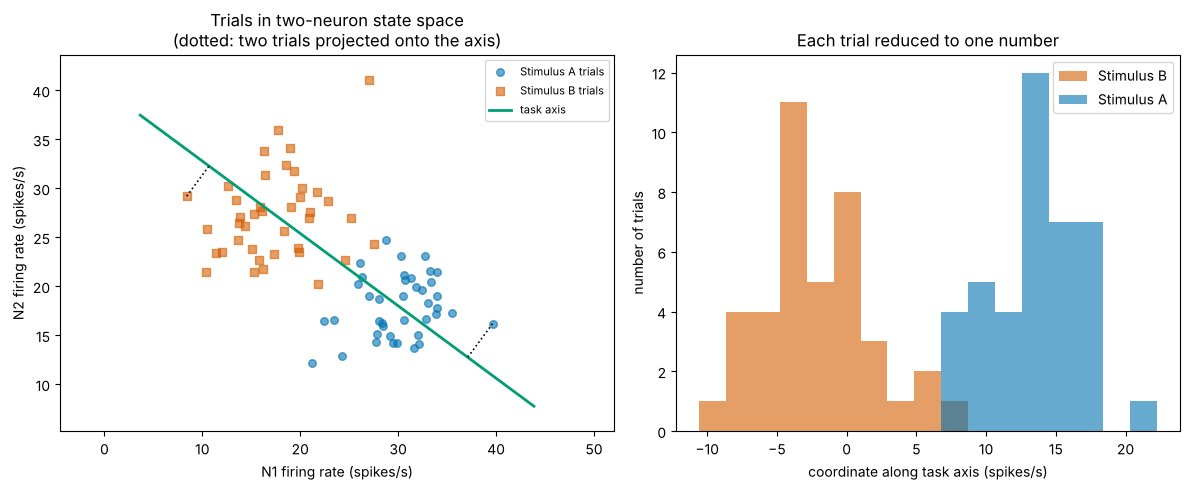

In [26]:
midpoint = (trials_A.mean(axis=0) + trials_B.mean(axis=0)) / 2
line_pts = midpoint + np.array([-25, 25])[:, None] * task_axis

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1.1, 1]})

ax = axes[0]
ax.scatter(trials_A[:, 0], trials_A[:, 1], color=PALETTE[0], marker=MARKERS[0], alpha=0.6, s=30, label='Stimulus A trials')
ax.scatter(trials_B[:, 0], trials_B[:, 1], color=PALETTE[1], marker=MARKERS[1], alpha=0.6, s=30, label='Stimulus B trials')
ax.plot(line_pts[:, 0], line_pts[:, 1], color=PALETTE[2], lw=2, label='task axis')
for trial in [trials_A[np.argmax(coords_A)], trials_B[np.argmin(coords_B)]]:     # two example trials, one per condition
    foot = midpoint + ((trial - midpoint) @ task_axis) * task_axis
    ax.plot([trial[0], foot[0]], [trial[1], foot[1]], ':', color='black', lw=1.2)
ax.set_xlabel('N1 firing rate (spikes/s)'); ax.set_ylabel('N2 firing rate (spikes/s)')
ax.set_aspect('equal', adjustable='datalim')
ax.set_title('Trials in two-neuron state space\n(dotted: two trials projected onto the axis)')
ax.legend(fontsize=8, loc='upper right')

ax = axes[1]
bins = np.linspace(min(coords_A.min(), coords_B.min()), max(coords_A.max(), coords_B.max()), 18)
ax.hist(coords_B, bins=bins, color=PALETTE[1], alpha=0.6, label='Stimulus B')
ax.hist(coords_A, bins=bins, color=PALETTE[0], alpha=0.6, label='Stimulus A')
ax.set_xlabel('coordinate along task axis (spikes/s)')
ax.set_ylabel('number of trials')
ax.set_title('Each trial reduced to one number')
ax.legend()
plt.tight_layout()
plt.show()

#### Interactive version

In [27]:
fig_interactive = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45],
                                subplot_titles=('Trials in two-neuron state space', 'Coordinates along the task axis'))
for trials, coords, colour, symbol, name in [(trials_A, coords_A, PALETTE[0], 'circle', 'Stimulus A'),
                                             (trials_B, coords_B, PALETTE[1], 'square', 'Stimulus B')]:
    fig_interactive.add_trace(go.Scatter(
        x=trials[:, 0], y=trials[:, 1], mode='markers', name=f'{name} trials',
        marker=dict(color=colour, symbol=symbol, size=8, opacity=0.65),
        customdata=np.stack([np.arange(n_trials), coords], axis=1),
        hovertemplate=(name + ', trial %{customdata[0]}<br>N1: %{x:.1f} spikes/s<br>N2: %{y:.1f} spikes/s'
                       '<br>axis coordinate: %{customdata[1]:.1f}<extra></extra>'),
    ), row=1, col=1)
    fig_interactive.add_trace(go.Histogram(x=coords, name=f'{name} coordinates', marker_color=colour, opacity=0.6,
                                           xbins=dict(start=bins[0], end=bins[-1], size=bins[1] - bins[0])), row=1, col=2)
fig_interactive.add_trace(go.Scatter(x=line_pts[:, 0], y=line_pts[:, 1], mode='lines', name='task axis',
                                     line=dict(color=PALETTE[2], width=3), hoverinfo='skip'), row=1, col=1)
fig_interactive.update_xaxes(title_text='N1 firing rate (spikes/s)', row=1, col=1)
fig_interactive.update_yaxes(title_text='N2 firing rate (spikes/s)', scaleanchor='x', scaleratio=1, row=1, col=1)
fig_interactive.update_xaxes(title_text='coordinate along task axis (spikes/s)', row=1, col=2)
fig_interactive.update_yaxes(title_text='number of trials', row=1, col=2)
fig_interactive.update_layout(barmode='overlay', template='plotly_white', width=1100, height=520,
                              title='Projecting trials onto a task axis (hover a trial to see its coordinate)')
fig_interactive.show(config=PLOTLY_CONFIG)

**Interpretation:** two neurons' worth of data per trial have been reduced to one number, and the two conditions separate well along it. The task axis is a choice: a different pair of conditions defines a different axis and different coordinates. A clean separation shows the information is *present* in the population, not that the brain *uses* this axis.

# **Part 9: Weighted Sums and Bias: the First Linear Stage of a Neuron**

Part 1 computed a neuron's total weighted input. Simple neuron models add one more number, a **bias** $b$:

$$z = \mathbf{w}\cdot\mathbf{x} + b$$

The bias shifts the total up or down whatever the inputs are, like a resting level of excitability. It is a separate number, not one of the products in the dot product.

In a rate model, $z$ is then passed through a nonlinearity (for example, firing rates cannot be negative). That second stage is Lesson 4's topic. Here we look only at the linear stage $z$.

In [28]:
x_pre  = np.array([12.0, 30.0, 5.0, 20.0, 8.0])   # presynaptic rates, spikes/s, shape (5,)
w_syn  = np.array([0.6, -0.4, 0.0, 0.9, -0.2])     # weights (no units), shape (5,)
b_bias = 3.0                                       # spikes/s

contributions_syn = w_syn * x_pre
z_total = w_syn @ x_pre + b_bias

print("Contributions w_i x_i:", contributions_syn, "spikes/s")
print(f"w . x = {w_syn @ x_pre:.1f}   b = {b_bias}   z = w . x + b = {z_total:.1f} spikes/s")

Contributions w_i x_i: [  7.2 -12.    0.   18.   -1.6] spikes/s
w . x = 11.6   b = 3.0   z = w . x + b = 14.6 spikes/s


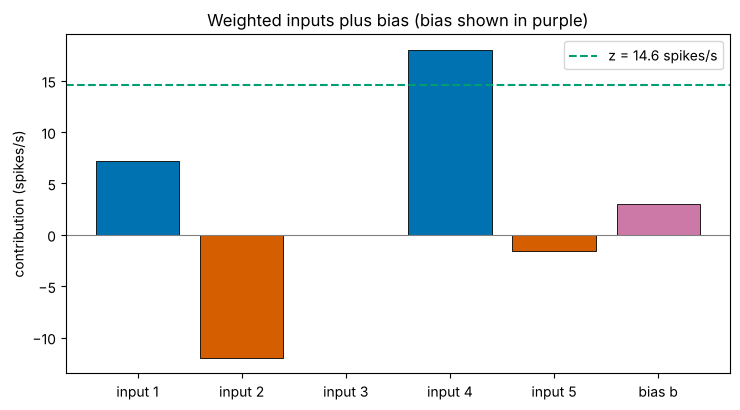

In [29]:
bar_labels = [f'input {i+1}' for i in range(len(x_pre))] + ['bias b']
bar_values = list(contributions_syn) + [b_bias]
bar_colours = [PALETTE[0] if val >= 0 else PALETTE[1] for val in contributions_syn] + [PALETTE[3]]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(bar_labels, bar_values, color=bar_colours, edgecolor='black', linewidth=0.6)
ax.axhline(0, color='grey', lw=0.8)
ax.axhline(z_total, color=PALETTE[2], ls='--', lw=1.5, label=f'z = {z_total:.1f} spikes/s')
ax.set_ylabel('contribution (spikes/s)')
ax.set_title('Weighted inputs plus bias (bias shown in purple)')
ax.legend()
plt.tight_layout()
plt.show()

#### Interactive version

In [30]:
fig_interactive = go.Figure(go.Bar(
    x=bar_labels, y=bar_values, marker_color=bar_colours, marker_line_color='black', marker_line_width=0.8,
    customdata=np.append(np.stack([w_syn, x_pre], axis=1), [[np.nan, np.nan]], axis=0),
    hovertemplate='%{x}<br>contribution = %{y:.2f} spikes/s<br>w = %{customdata[0]:.2f}, x = %{customdata[1]:.1f}<extra></extra>',
))
fig_interactive.add_hline(y=0, line_width=1, line_color='grey')
fig_interactive.add_hline(y=z_total, line_dash='dash', line_color=PALETTE[2],
                          annotation_text=f'z = {z_total:.1f}', annotation_position='top left')
fig_interactive.update_layout(title='Weighted inputs plus bias (hover for detail)', yaxis_title='contribution (spikes/s)',
                              template='plotly_white', width=720, height=440)
fig_interactive.show(config=PLOTLY_CONFIG)

**Try it.** Change one value at a time in the cell below and rerun it. Before each run, predict whether $z$ goes up or down, and by how much.

1. Set the weight of input 3 to `0.5`. Its input is only 5 spikes/s, so does it matter much?
2. Make the bias `-10`.
3. Double every input. What happens to $\mathbf{w}\cdot\mathbf{x}$, and what happens to $b$?

In [31]:
# EDIT these values and rerun.
w_try = np.array([0.6, -0.4, 0.0, 0.9, -0.2])
x_try = np.array([12.0, 30.0, 5.0, 20.0, 8.0])
b_try = 3.0

print(f"w . x = {w_try @ x_try:.1f} spikes/s,  b = {b_try},  z = {w_try @ x_try + b_try:.1f} spikes/s")

w . x = 11.6 spikes/s,  b = 3.0,  z = 14.6 spikes/s


### The weight vector as a preferred direction

Read geometrically, $\mathbf{w}$ is a **direction** in input space. Hold the input strength fixed and rotate its direction by an angle $\phi$. The response is

$$z(\phi) = \mathbf{w}\cdot\mathbf{x}(\phi) = \lVert\mathbf{w}\rVert\,\lVert\mathbf{x}\rVert\cos(\phi - \phi_w)$$

This is the Part 3 cosine curve again, now read as a **tuning curve**. The response is largest when the stimulus lines up with the neuron's **preferred direction** $\phi_w$. Neurons in motor cortex were famously described this way (Georgopoulos et al., 1982).

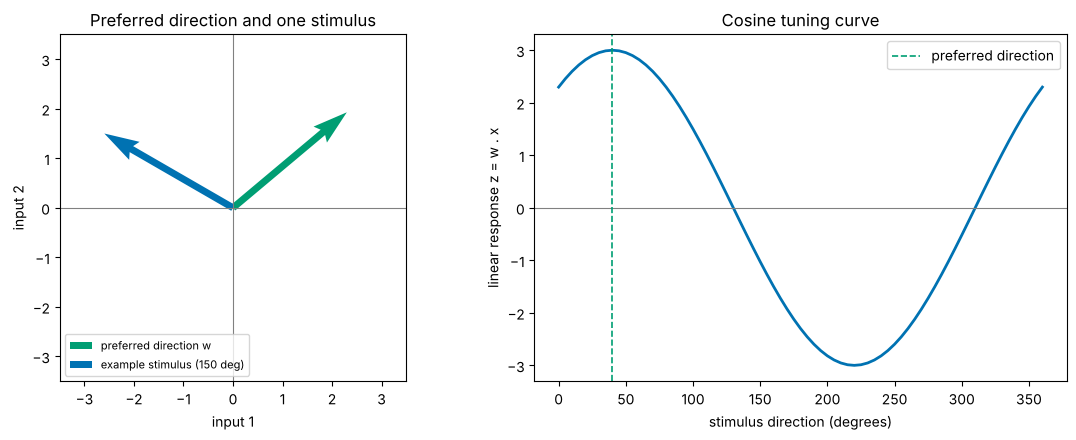

In [32]:
preferred_deg = 40.0
w_preferred = np.array([np.cos(np.radians(preferred_deg)), np.sin(np.radians(preferred_deg))])   # unit vector
stim_strength = 3.0

stim_deg = np.arange(0, 361, 5)
stimuli = stim_strength * np.stack([np.cos(np.radians(stim_deg)), np.sin(np.radians(stim_deg))], axis=1)   # shape (n_angles, 2)
tuning = stimuli @ w_preferred                                                                            # shape (n_angles,)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
ax = axes[0]
qkw = dict(angles='xy', scale_units='xy', scale=1, width=0.02)
ax.quiver(0, 0, *(stim_strength * w_preferred), color=PALETTE[2], label='preferred direction w', **qkw)
ax.quiver(0, 0, *stimuli[30], color=PALETTE[0], label=f'example stimulus ({stim_deg[30]} deg)', **qkw)
ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect('equal')
ax.set_xlabel('input 1'); ax.set_ylabel('input 2')
ax.set_title('Preferred direction and one stimulus')
ax.legend(fontsize=8, loc='lower left')

ax = axes[1]
ax.plot(stim_deg, tuning, color=PALETTE[0], lw=2)
ax.axhline(0, color='grey', lw=0.8)
ax.axvline(preferred_deg, color=PALETTE[2], ls='--', lw=1.2, label='preferred direction')
ax.set_xlabel('stimulus direction (degrees)'); ax.set_ylabel('linear response z = w . x')
ax.set_title('Cosine tuning curve')
ax.legend()
plt.tight_layout()
plt.show()

#### Animation: rotate the stimulus along the tuning curve

In [33]:
# INTERACTIVE ANIMATION -- the stimulus rotates; its response moves along the tuning curve
fig_tuning = make_subplots(rows=1, cols=2, subplot_titles=('Stimulus and preferred direction', 'Tuning curve'))
fig_tuning.add_trace(go.Scatter(x=[0, stim_strength * w_preferred[0]], y=[0, stim_strength * w_preferred[1]], mode='lines',
                                name='preferred direction w', line=dict(color=PALETTE[2], width=5)), row=1, col=1)
fig_tuning.add_trace(go.Scatter(x=[0, stimuli[0, 0]], y=[0, stimuli[0, 1]], mode='lines',
                                name='stimulus x', line=dict(color=PALETTE[0], width=5)), row=1, col=1)
fig_tuning.add_trace(go.Scatter(x=stim_deg, y=tuning, mode='lines', name='tuning curve',
                                line=dict(color='lightgrey', width=2), hoverinfo='skip'), row=1, col=2)
fig_tuning.add_trace(go.Scatter(x=[stim_deg[0]], y=[tuning[0]], mode='markers', name='current response',
                                marker=dict(color=PALETTE[0], size=12)), row=1, col=2)
fig_tuning.add_vline(x=preferred_deg, line_dash='dash', line_color=PALETTE[2], row=1, col=2)
fig_tuning.add_hline(y=0, line_width=1, line_color='grey', row=1, col=2)
fig_tuning.frames = [
    go.Frame(name=str(k), traces=[1, 3], data=[
        go.Scatter(x=[0, stimuli[k, 0]], y=[0, stimuli[k, 1]]),
        go.Scatter(x=[stim_deg[k]], y=[tuning[k]]),
    ])
    for k in range(len(stim_deg))
]
buttons, sliders = play_pause_and_slider([f'{a} deg' for a in stim_deg], prefix='stimulus direction = ')
fig_tuning.update_xaxes(range=[-3.5, 3.5], title_text='input 1', scaleanchor='y', scaleratio=1, row=1, col=1)
fig_tuning.update_yaxes(range=[-3.5, 3.5], title_text='input 2', row=1, col=1)
fig_tuning.update_xaxes(range=[0, 360], title_text='stimulus direction (degrees)', row=1, col=2)
fig_tuning.update_yaxes(range=list(padded_limits(tuning)), title_text='linear response z', row=1, col=2)
fig_tuning.update_layout(title='A dot-product neuron is a cosine-tuned neuron', template='plotly_white',
                         width=1000, height=520, updatemenus=buttons, sliders=sliders)
fig_tuning.show(config=PLOTLY_CONFIG)

**Limitations.** Real tuning curves have a baseline firing rate, cannot go below zero, saturate, and are noisy. A positive model weight is not automatically an excitatory synapse, nor a negative one an inhibitory synapse. The dot product captures only the linear part of the neuron's computation.

# **Part 10: The Same Computation in a Linear Classifier**

Machine learning uses the identical formula. A **linear classifier** scores an observation $\mathbf{x}$ with $z = \mathbf{w}\cdot\mathbf{x} + b$ and predicts class 1 if $z > 0$, class 0 otherwise.

Geometry from this lesson explains what it does:

- The **decision boundary** is where $z = 0$, i.e. $\mathbf{w}\cdot\mathbf{x} = -b$. In 2D this is a straight line, and it is **orthogonal to $\mathbf{w}$** (Part 4).
- $z / \lVert\mathbf{w}\rVert$ is the signed distance from the boundary, measured along $\hat{\mathbf{w}}$: a projection (Part 7).
- Changing $b$ slides the boundary along $\mathbf{w}$ without turning it.

Below, two features have been measured for 30 observations of each class (simulated, standardised units). The weights are set by hand; learning them from data comes later in the course.

In [34]:
n_per_class = 30
X_class0 = RNG.normal([-1.0, -0.5], 0.7, size=(n_per_class, 2))   # shape (30, 2): (observation, feature)
X_class1 = RNG.normal([1.2, 0.9], 0.7, size=(n_per_class, 2))
X = np.vstack([X_class0, X_class1])                              # shape (60, 2)
y = np.array([0] * n_per_class + [1] * n_per_class)              # true class labels, shape (60,)

w_clf = np.array([1.0, 0.8])
b_clf = -0.2

scores = X @ w_clf + b_clf                 # one score per observation, shape (60,)
predictions = (scores > 0).astype(int)
accuracy = np.mean(predictions == y)
print(f"X shape: {X.shape} (n_observations, n_features)")
print(f"Accuracy with w = {w_clf}, b = {b_clf}: {accuracy:.0%}")

X shape: (60, 2) (n_observations, n_features)
Accuracy with w = [1.  0.8], b = -0.2: 98%


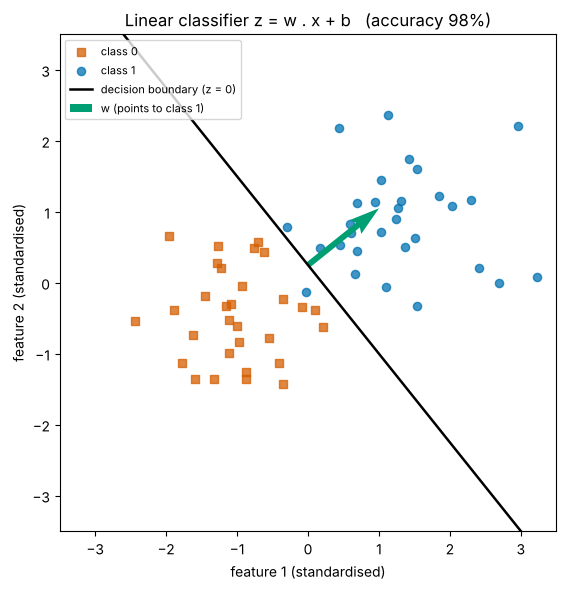

In [35]:
x1_line = np.linspace(-3.5, 3.5, 2)
x2_line = -(w_clf[0] * x1_line + b_clf) / w_clf[1]     # solve w1 x1 + w2 x2 + b = 0 for x2

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(X_class0[:, 0], X_class0[:, 1], color=PALETTE[1], marker=MARKERS[1], s=35, alpha=0.75, label='class 0')
ax.scatter(X_class1[:, 0], X_class1[:, 1], color=PALETTE[0], marker=MARKERS[0], s=35, alpha=0.75, label='class 1')
ax.plot(x1_line, x2_line, color='black', lw=1.8, label='decision boundary (z = 0)')
ax.quiver(0, -b_clf / w_clf[1], *w_clf, angles='xy', scale_units='xy', scale=1, color=PALETTE[2], width=0.012, label='w (points to class 1)')
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); ax.set_aspect('equal')
ax.set_xlabel('feature 1 (standardised)'); ax.set_ylabel('feature 2 (standardised)')
ax.set_title(f'Linear classifier z = w . x + b   (accuracy {accuracy:.0%})')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

#### Interactive version

In [36]:
fig_interactive = go.Figure()
for cls, colour, symbol in [(0, PALETTE[1], 'square'), (1, PALETTE[0], 'circle')]:
    mask = y == cls
    fig_interactive.add_trace(go.Scatter(
        x=X[mask, 0], y=X[mask, 1], mode='markers', name=f'class {cls}',
        marker=dict(color=colour, symbol=symbol, size=9, opacity=0.8),
        customdata=np.stack([scores[mask], predictions[mask]], axis=1),
        hovertemplate='feature 1: %{x:.2f}<br>feature 2: %{y:.2f}<br>score z: %{customdata[0]:.2f}<br>predicted class: %{customdata[1]}<extra></extra>',
    ))
fig_interactive.add_trace(go.Scatter(x=x1_line, y=x2_line, mode='lines', name='decision boundary (z = 0)',
                                     line=dict(color='black', width=2), hoverinfo='skip'))
fig_interactive.update_layout(
    title='Linear classifier (hover a point to see its score)',
    xaxis=dict(title='feature 1 (standardised)', range=[-3.5, 3.5]),
    yaxis=dict(title='feature 2 (standardised)', range=[-3.5, 3.5], scaleanchor='x', scaleratio=1),
    template='plotly_white', width=680, height=640,
)
fig_interactive.show(config=PLOTLY_CONFIG)

**Try it.** Change `b_clf` to `-2.0`, then to `2.0`, and rerun the three cells above. Which way does the boundary move, and what happens to accuracy? Then change `w_clf` to `[1.0, -0.8]`. Why does the boundary *turn* this time?

The neuron of Part 9 and the classifier here are the same computation, $\mathbf{w}\cdot\mathbf{x} + b$. This is the first, linear stage of almost every neural network model.

# **Part 11: Mini-Lab — Decoding a Stimulus with Dot Products**

This mini-lab combines the lesson into one analysis, using the Part 8 recording. It needs no internet access or external files.

**Your task, worked through below:**
1. Compare the two condition means with cosine similarity and the angle between them.
2. Build the task axis from the recorded trials.
3. Turn the axis into a decoder $z = \mathbf{w}\cdot\mathbf{r} + b$ that says "A" when $z > 0$.
4. Test the decoder on **new** trials that were not used to build it.
5. Write a scientific interpretation and note a limitation.

In [37]:
# Step 1: compare the condition means
mean_A_hat, mean_B_hat = trials_A.mean(axis=0), trials_B.mean(axis=0)
print(f"Mean response A: {np.round(mean_A_hat, 1)} spikes/s,  mean response B: {np.round(mean_B_hat, 1)} spikes/s")
print(f"Cosine similarity of the two means: {cosine_similarity(mean_A_hat, mean_B_hat):.3f}")
print(f"Angle between the two means       : {angle_between(mean_A_hat, mean_B_hat):.1f} degrees")

# Steps 2-3: task axis as the weight vector; bias puts the boundary halfway between the two means
w_decoder = task_axis
b_decoder = -(midpoint @ w_decoder)
print(f"\nDecoder weights w = {np.round(w_decoder, 3)},  bias b = {b_decoder:.2f} spikes/s")

# Step 4: new trials from the same two conditions
test_A = mean_A + RNG.normal(0.0, noise_sd, size=(n_trials, 2))
test_B = mean_B + RNG.normal(0.0, noise_sd, size=(n_trials, 2))
z_test_A = test_A @ w_decoder + b_decoder
z_test_B = test_B @ w_decoder + b_decoder
accuracy_test = (np.sum(z_test_A > 0) + np.sum(z_test_B <= 0)) / (2 * n_trials)

z_train_A = trials_A @ w_decoder + b_decoder
z_train_B = trials_B @ w_decoder + b_decoder
accuracy_train = (np.sum(z_train_A > 0) + np.sum(z_train_B <= 0)) / (2 * n_trials)

print(f"\nAccuracy on the trials used to build the decoder: {accuracy_train:.0%}")
print(f"Accuracy on new trials                          : {accuracy_test:.0%}")

Mean response A: [30.1 18. ] spikes/s,  mean response B: [17.5 27.3] spikes/s
Cosine similarity of the two means: 0.895
Angle between the two means       : 26.5 degrees

Decoder weights w = [ 0.804 -0.594],  bias b = -5.67 spikes/s

Accuracy on the trials used to build the decoder: 98%
Accuracy on new trials                          : 98%


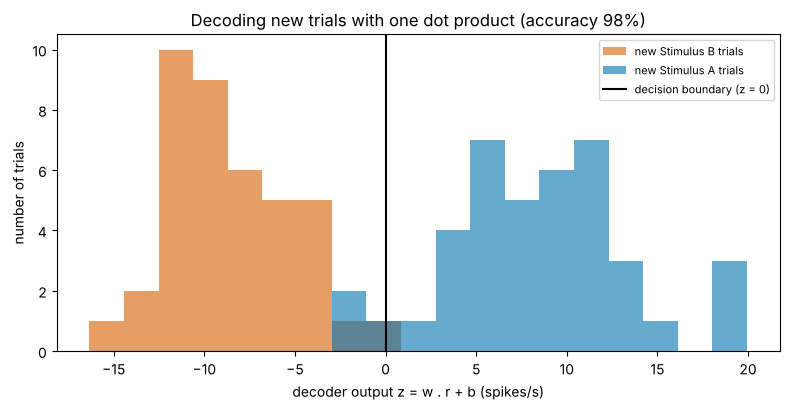

In [38]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(min(z_test_A.min(), z_test_B.min()), max(z_test_A.max(), z_test_B.max()), 20)
ax.hist(z_test_B, bins=bins, color=PALETTE[1], alpha=0.6, label='new Stimulus B trials')
ax.hist(z_test_A, bins=bins, color=PALETTE[0], alpha=0.6, label='new Stimulus A trials')
ax.axvline(0, color='black', lw=1.5, label='decision boundary (z = 0)')
ax.set_xlabel('decoder output z = w . r + b (spikes/s)')
ax.set_ylabel('number of trials')
ax.set_title(f'Decoding new trials with one dot product (accuracy {accuracy_test:.0%})')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation:** the two condition means have a high cosine similarity, partly because both are all-positive firing-rate vectors (Part 6). High similarity did not stop the conditions being told apart: projecting onto the axis that separates them gives a one-number decoder that classifies new trials well above the 50% chance level. Similarity of the *means* and separability of the *trials* are different questions.

**Limitation:** this is simulated data with equal, independent noise in both neurons, and only two neurons. The axis was the simple difference of means; with correlated noise a better axis exists (Week 2 builds the tools). Accuracy measured on the same trials used to build a decoder is optimistic, which is why Step 4 used new trials (Lesson 5 returns to this train/test separation).

# **Part 12: Summary and Lesson 3 Preview**

| Idea | Formula | What it tells you |
|---|---|---|
| Dot product | $\mathbf{u}\cdot\mathbf{v} = \sum_i u_i v_i$ | Sum of matched products |
| Geometric form | $\lVert\mathbf{u}\rVert\,\lVert\mathbf{v}\rVert\cos\theta$ | Same number, as lengths and an angle |
| Orthogonality | $\mathbf{u}\cdot\mathbf{v} = 0$ | Right angle; one does not affect the other's read-out |
| Cosine similarity | $\hat{\mathbf{u}}\cdot\hat{\mathbf{v}}$ | Pattern only, strength removed |
| Scalar projection | $\mathbf{u}\cdot\hat{\mathbf{v}}$ | Coordinate of $\mathbf{u}$ along $\mathbf{v}$ |
| Vector projection | $\frac{\mathbf{u}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}$ | The part of $\mathbf{u}$ along $\mathbf{v}$ |
| Projection error | $\lVert\mathbf{u} - \operatorname{proj}_{\mathbf{v}}(\mathbf{u})\rVert$ | What the direction misses; shortest distance to the line |
| Weighted sum with bias | $z = \mathbf{w}\cdot\mathbf{x} + b$ | A neuron's linear input; a classifier's score |

**Lesson 3** stacks many vectors into a **matrix**: many trials, many neurons, many weight vectors. You already used one in Part 8, where `trials_A` held one trial per row. And `trials_A @ task_axis` computed one dot product per row: that is a matrix–vector product, which Lesson 4 develops.